# Comparing the three methods

All methods are scored the same way: estimate each player's per-90 rates from season *t*, then compare with the
same player's per-90 rates in season *t+1* (players with 600+ minutes in *t+1*).
The baseline is the raw per-90 number. A method is useful only if it beats the baseline for low-minute players.

In [1]:
import sys
sys.path.append("..")  # so we can import the analysis/ folder from the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from analysis import common
from analysis import minutes_shrinkage as ms
from analysis import optimal_transport as otm
from analysis import similar_player_prediction as sp
sns.set_theme(style="whitegrid", context="notebook")

GENDER, ROLE = "female", "FW"   # the player pool for every experiment
STAT = "goals"                  # the stat we zoom in on in plots

con = common.connect()
terms = common.load_player_terms(con, GENDER, ROLE)          # one row per player-season
pairs = common.make_next_year_pairs(terms, ROLE)             # season t paired with season t+1
raw, target, minutes = common.split_pairs(pairs, ROLE)       # raw per-90, next-year per-90, minutes
all_rates = common.per90(terms, ROLE)                        # per-90 for every player-season
print(f"{len(terms):,} player-seasons, {len(pairs):,} with a usable next season")

5,941 player-seasons, 1,726 with a usable next season


In [2]:
# Method 1: shrinkage
k = ms.estimate_all_k(all_rates, terms["minutes"])
means = pd.Series({s: ms.group_mean(all_rates[s], terms["minutes"]) for s in all_rates})
shrunk = ms.shrink(raw, minutes, k, means)

# Method 2: optimal transport
reference = otm.fit_reference(all_rates, terms["minutes"])
ot_1d = otm.transport_low_minutes(raw, minutes, reference, how="1d")
ot_sinkhorn = otm.transport_low_minutes(raw, minutes, reference, how="sinkhorn")

# Method 3: similar players
matches = common.load_player_matches(con, GENDER, ROLE)
sim = sp.simulate_low_minutes(matches, ROLE)
similar = sp.cross_fitted_predict(sim, raw, minutes, pairs["player_id"], ROLE)

estimates = {"raw": raw, "1 shrinkage": shrunk, "2a OT 1-D": ot_1d,
             "2b OT Sinkhorn": ot_sinkhorn, "3 similar players": similar}
results = {name: common.evaluate(est, target, minutes) for name, est in estimates.items()}

## Scores by minute bucket

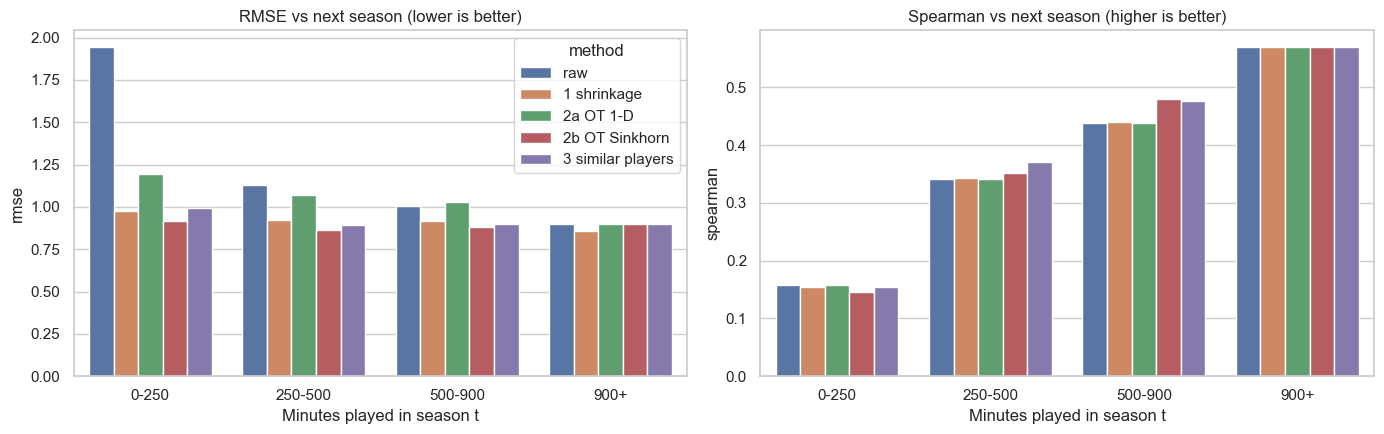

In [3]:
table = pd.concat(results, names=["method"]).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric, title in zip(axes, ["rmse", "spearman"],
                             ["RMSE vs next season (lower is better)", "Spearman vs next season (higher is better)"]):
    sns.barplot(data=table[table["bucket"] != "all"], x="bucket", y=metric, hue="method", ax=ax)
    ax.set_title(title); ax.set_xlabel("Minutes played in season t")
    if metric == "spearman":
        ax.legend().remove()
plt.tight_layout(); plt.show()

In [4]:
summary = table.pivot(index="method", columns="bucket", values="rmse")[["all"] + common.BUCKET_LABELS]
print("RMSE (lower is better)"); display(summary.round(3))
summary = table.pivot(index="method", columns="bucket", values="spearman")[["all"] + common.BUCKET_LABELS]
print("Spearman (higher is better)"); display(summary.round(3))

RMSE (lower is better)


bucket,all,0-250,250-500,500-900,900+
method,,,,,
1 shrinkage,0.900,0.973,0.921,0.918,0.856
2a OT 1-D,1.007,1.196,1.068,1.031,0.902
2b OT Sinkhorn,0.894,0.916,0.865,0.880,0.902
3 similar players,0.914,0.996,0.890,0.898,0.902
raw,1.150,1.945,1.127,1.004,0.902


Spearman (higher is better)


bucket,all,0-250,250-500,500-900,900+
method,,,,,
1 shrinkage,0.466,0.154,0.343,0.440,0.570
2a OT 1-D,0.450,0.157,0.341,0.438,0.569
2b OT Sinkhorn,0.460,0.147,0.352,0.479,0.569
3 similar players,0.473,0.155,0.370,0.477,0.569
raw,0.450,0.157,0.341,0.438,0.569


## Improvement over raw, per stat (players under 500 minutes)

Which stats gain the most? Each bar is the drop in error compared with the raw number
(positive = better than raw).

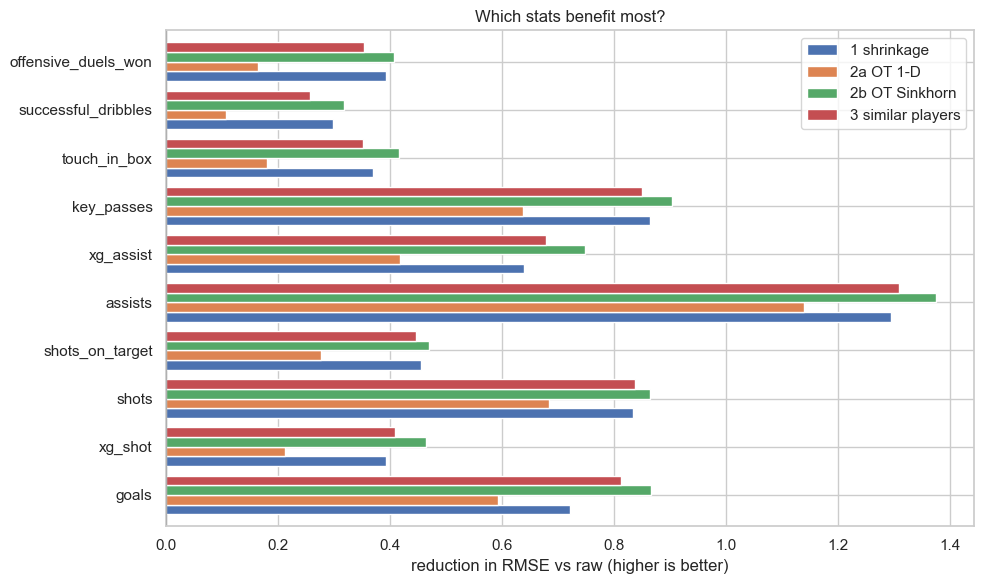

In [5]:
short = minutes < 500
scale = target.std()

def stat_error(est):
    return np.sqrt((((est[short] - target[short]) / scale) ** 2).mean())

baseline = stat_error(raw)
gain = pd.DataFrame({name: baseline - stat_error(est) for name, est in estimates.items() if name != "raw"})
gain.plot.barh(figsize=(10, 6), width=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("reduction in RMSE vs raw (higher is better)")
plt.title("Which stats benefit most?")
plt.tight_layout(); plt.show()

## Conclusions

Based on the run above (female forwards; scores against next season):

* **Best at the lowest minutes (0-250):** Sinkhorn OT has the lowest RMSE (0.92), with shrinkage close behind (0.97).
  Raw is far worse (1.95). No method improves Spearman here: with so few minutes, the ordering of players is almost pure noise.
* **Best ranking of players (Spearman):** similar-player prediction, mainly in the 250-500 bucket (0.377 vs 0.341 raw), with Sinkhorn OT close in 500-900.
* **Easiest to explain and maintain:** shrinkage, which is one number per stat and also the best method for the 900+ group.
* **OT 1-D** fixes the spread but cannot reorder players, so it trails the other three.
* **Biggest risk of each method:** shrinkage ignores a player's other stats; OT assumes low-minute players are as good as the
  reference group; similar-player prediction assumes random matches look like a real bench player's matches.
* **Next steps:** other position groups and men's data; a hybrid (shrinkage toward the similar-player prediction instead of the group mean);
  repeat with the next-season minutes threshold changed.